# Keras ANN (은닉층 1개) - EuroSAT 이미지 분류
6개 모델(ANN/DNN/CNN x Keras/PyTorch) 비교 실험의 첫 번째 모델입니다.
결과는 Drive의 `model_results.csv`에 한 줄씩 누적 저장되어, 나중에 전체 비교에 사용됩니다.

In [ ]:
# 백업해둔 zip 풀어서 사용
from google.colab import drive
drive.mount('/content/drive')

import os, shutil

SPLIT_DIR = '/content/eurosat_split'
DRIVE_ZIP = '/content/drive/MyDrive/eurosat_split.zip'

if not os.path.exists(SPLIT_DIR) and os.path.exists(DRIVE_ZIP):
    shutil.unpack_archive(DRIVE_ZIP, SPLIT_DIR)
    print('Drive에서 압축 해제 완료')
else:
    print('SPLIT_DIR 이미 존재하거나 Drive 백업이 없습니다. 경로를 확인하세요:', SPLIT_DIR)

Mounted at /content/drive
Drive에서 압축 해제 완료


In [ ]:
# 데이터 로딩, 배치 단위로 불러오기
import tensorflow as tf

print('GPU 사용 가능:', tf.config.list_physical_devices('GPU'))

IMG_SIZE = (64, 64)
BATCH_SIZE = 32

train_ds = tf.keras.utils.image_dataset_from_directory(
    os.path.join(SPLIT_DIR, 'train'), image_size=IMG_SIZE, batch_size=BATCH_SIZE, seed=42)
val_ds = tf.keras.utils.image_dataset_from_directory(
    os.path.join(SPLIT_DIR, 'val'), image_size=IMG_SIZE, batch_size=BATCH_SIZE, seed=42)
test_ds = tf.keras.utils.image_dataset_from_directory(
    os.path.join(SPLIT_DIR, 'test'), image_size=IMG_SIZE, batch_size=BATCH_SIZE, seed=42)

class_names = train_ds.class_names
num_classes = len(class_names)
print('클래스 수:', num_classes)
print(class_names)

GPU 사용 가능: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]
Found 18900 files belonging to 10 classes.
Found 4050 files belonging to 10 classes.
Found 4050 files belonging to 10 classes.
클래스 수: 10
['AnnualCrop', 'Forest', 'HerbaceousVegetation', 'Highway', 'Industrial', 'Pasture', 'PermanentCrop', 'Residential', 'River', 'SeaLake']


In [ ]:
# 픽셀 정규화(0~1) + 성능을 위한 프리페치
normalization_layer = tf.keras.layers.Rescaling(1./255)

AUTOTUNE = tf.data.AUTOTUNE
train_ds = train_ds.map(lambda x, y: (normalization_layer(x), y)).cache().prefetch(AUTOTUNE)
val_ds = val_ds.map(lambda x, y: (normalization_layer(x), y)).cache().prefetch(AUTOTUNE)
test_ds = test_ds.map(lambda x, y: (normalization_layer(x), y)).cache().prefetch(AUTOTUNE)

## 2. ANN 모델 정의
은닉층 1개짜리 완전연결 신경망입니다. 이미지를 1차원으로 펼친(Flatten) 뒤 Dense층 하나만 거칩니다.
DNN(은닉층 여러 개)과의 차이를 보여주기 위한 베이스라인입니다.

In [ ]:
def build_ann(input_shape, num_classes):
    model = tf.keras.Sequential([
        tf.keras.layers.Input(shape=input_shape),
        tf.keras.layers.Flatten(),
        tf.keras.layers.Dense(256, activation='relu', kernel_initializer='he_normal'),
        tf.keras.layers.Dropout(0.3),
        tf.keras.layers.Dense(num_classes, activation='softmax'),
    ])
    return model

model = build_ann((64, 64, 3), num_classes)
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ flatten (Flatten)               │ (None, 12288)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 256)            │     3,145,984 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 10)             │         2,570 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 3,148,554 (12.01 MB)

 Trainable params: 3,148,554 (12.01 MB)

 Non-trainable params: 0 (0.00 B)

## 3. 컴파일 및 콜백 설정

In [ ]:
model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy'],
)

callbacks = [
    tf.keras.callbacks.EarlyStopping(patience=5, restore_best_weights=True),
    tf.keras.callbacks.ReduceLROnPlateau(factor=0.5, patience=3),
]

## 4. 학습

In [ ]:
import time

start_time = time.time()

history = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=50,
    callbacks=callbacks,
)

training_time = time.time() - start_time
print(f'학습 시간: {training_time:.1f}초')

Epoch 1/50
591/591 ━━━━━━━━━━━━━━━━━━━━ 10s 12ms/step - accuracy: 0.1806 - loss: 2.2244 - val_accuracy: 0.2284 - val_loss: 1.8856 - learning_rate: 0.0010
Epoch 2/50
591/591 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - accuracy: 0.1951 - loss: 1.9824 - val_accuracy: 0.2595 - val_loss: 1.8923 - learning_rate: 0.0010
Epoch 3/50
591/591 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step - accuracy: 0.1989 - loss: 1.9816 - val_accuracy: 0.2472 - val_loss: 1.8464 - learning_rate: 0.0010
Epoch 4/50
591/591 ━━━━━━━━━━━━━━━━━━━━ 3s 4ms/step - accuracy: 0.2044 - loss: 1.9735 - val_accuracy: 0.3049 - val_loss: 1.8325 - learning_rate: 0.0010
Epoch 5/50
591/591 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - accuracy: 0.2115 - loss: 1.9634 - val_accuracy: 0.3000 - val_loss: 1.8741 - learning_rate: 0.0010
Epoch 6/50
591/591 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - accuracy: 0.2071 - loss: 1.9633 - val_accuracy: 0.2617 - val_loss: 1.8690 - learning_rate: 0.0010
Epoch 7/50
591/591 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - accuracy: 0.2130 - loss: 1.9676 

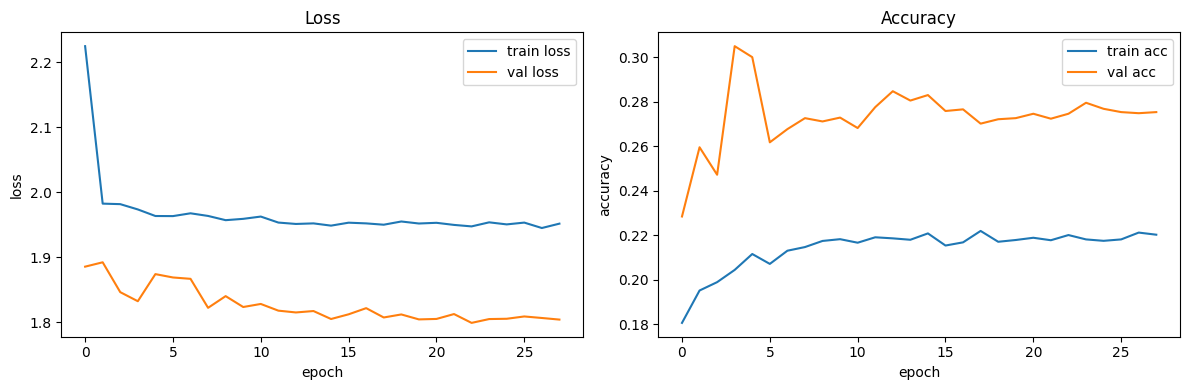

In [ ]:
# 학습 곡선 시각화하기
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].plot(history.history['loss'], label='train loss')
axes[0].plot(history.history['val_loss'], label='val loss')
axes[0].set_xlabel('epoch'); axes[0].set_ylabel('loss'); axes[0].legend(); axes[0].set_title('Loss')

axes[1].plot(history.history['accuracy'], label='train acc')
axes[1].plot(history.history['val_accuracy'], label='val acc')
axes[1].set_xlabel('epoch'); axes[1].set_ylabel('accuracy'); axes[1].legend(); axes[1].set_title('Accuracy')

plt.tight_layout()
plt.show()

6. Test 평가 및 결과 기록

테스트 정확도/손실, 파라미터 수, 학습 시간을 공용 CSV(`model_results.csv`)에 한 줄 추가합니다.
이 파일은 이후 DNN, CNN, PyTorch 버전 노트북에서도 같은 방식으로 계속 누적됩니다.

In [ ]:
test_loss, test_acc = model.evaluate(test_ds)
num_params = model.count_params()

print(f'Test accuracy: {test_acc:.4f}')
print(f'Test loss: {test_loss:.4f}')
print(f'파라미터 수: {num_params:,}')

127/127 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - accuracy: 0.2738 - loss: 1.7916
Test accuracy: 0.2738
Test loss: 1.7916
파라미터 수: 3,148,554


In [ ]:
import pandas as pd

RESULTS_PATH = '/content/drive/MyDrive/model_results.csv'

row = {
    'model': 'ANN',
    'framework': 'Keras',
    'test_accuracy': test_acc,
    'test_loss': test_loss,
    'num_params': num_params,
    'training_time_sec': training_time,
    'epochs_ran': len(history.history['loss']),
}

if os.path.exists(RESULTS_PATH):
    results_df = pd.read_csv(RESULTS_PATH)
    results_df = results_df[~((results_df['model'] == row['model']) & (results_df['framework'] == row['framework']))]
    results_df = pd.concat([results_df, pd.DataFrame([row])], ignore_index=True)
else:
    results_df = pd.DataFrame([row])

results_df.to_csv(RESULTS_PATH, index=False)
results_df

,model,framework,test_accuracy,test_loss,num_params,training_time_sec,epochs_ran
0,DNN,Keras,0.353580,1.670078,6457482,44.121216,14
1,ANN,PyTorch,0.446420,1.503735,3148554,178.828007,16
2,DNN,PyTorch,0.430864,1.526692,6457482,215.528363,17
3,CNN,Keras,0.873086,0.429663,2194122,81.434472,14
4,CNN,PyTorch,0.947407,0.190860,2193674,513.813921,34
5,ANN,Keras,0.273827,1.791635,3148554,65.389723,28
